In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [4]:
img = cv2.imread('c.jpg')
type(img), img.shape

(numpy.ndarray, (148, 148, 3))

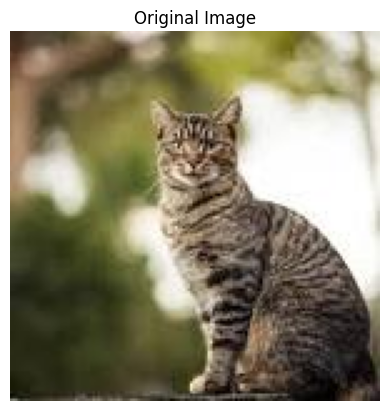

In [5]:
img = plt.imread("c.jpg")

plt.figure()
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

100%|██████████| 26.4M/26.4M [01:16<00:00, 348kB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 125kB/s]
100%|██████████| 4.42M/4.42M [00:09<00:00, 481kB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 45.2MB/s]


Epoch [1/50] | D Loss: 0.7374 | G Loss: 3.6743
Epoch [2/50] | D Loss: 0.4495 | G Loss: 2.6000
Epoch [3/50] | D Loss: 0.8863 | G Loss: 1.9754
Epoch [4/50] | D Loss: 0.6660 | G Loss: 1.8087
Epoch [5/50] | D Loss: 0.9820 | G Loss: 1.7646
Epoch [6/50] | D Loss: 0.7171 | G Loss: 3.0136
Epoch [7/50] | D Loss: 0.8063 | G Loss: 2.6241
Epoch [8/50] | D Loss: 1.1775 | G Loss: 1.1552
Epoch [9/50] | D Loss: 1.1654 | G Loss: 1.5097
Epoch [10/50] | D Loss: 1.3264 | G Loss: 1.2310


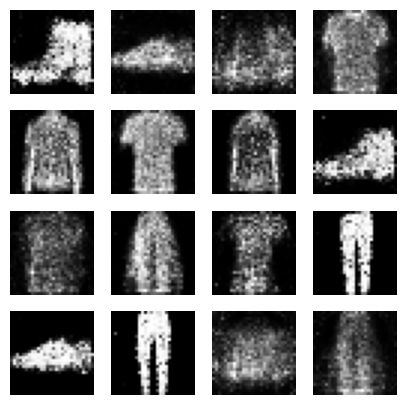

Epoch [11/50] | D Loss: 1.0849 | G Loss: 1.1197
Epoch [12/50] | D Loss: 1.1964 | G Loss: 1.4660
Epoch [13/50] | D Loss: 1.0016 | G Loss: 1.2492
Epoch [14/50] | D Loss: 1.1536 | G Loss: 1.1275
Epoch [15/50] | D Loss: 1.1580 | G Loss: 1.2392
Epoch [16/50] | D Loss: 1.1806 | G Loss: 0.8992
Epoch [17/50] | D Loss: 1.1333 | G Loss: 1.0434
Epoch [18/50] | D Loss: 1.2471 | G Loss: 1.1331
Epoch [19/50] | D Loss: 1.2154 | G Loss: 1.4273
Epoch [20/50] | D Loss: 1.2818 | G Loss: 0.9328


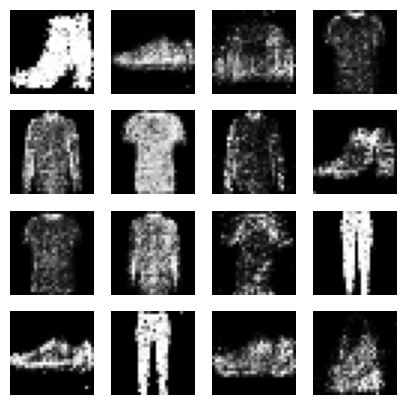

Epoch [21/50] | D Loss: 1.2042 | G Loss: 0.9775
Epoch [22/50] | D Loss: 1.3121 | G Loss: 1.0577
Epoch [23/50] | D Loss: 1.2708 | G Loss: 1.2543
Epoch [24/50] | D Loss: 1.2361 | G Loss: 1.0398
Epoch [25/50] | D Loss: 1.2229 | G Loss: 1.0576
Epoch [26/50] | D Loss: 1.1918 | G Loss: 0.9802
Epoch [27/50] | D Loss: 1.3129 | G Loss: 0.9122
Epoch [28/50] | D Loss: 1.2796 | G Loss: 1.1271
Epoch [29/50] | D Loss: 1.3966 | G Loss: 1.0269
Epoch [30/50] | D Loss: 1.4203 | G Loss: 1.0058


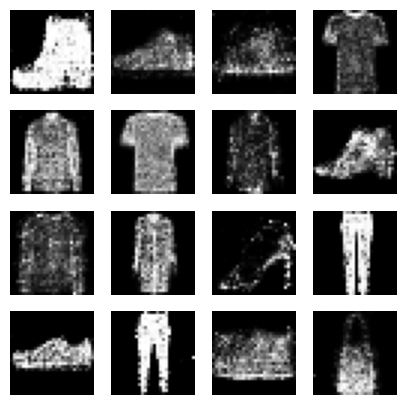

Epoch [31/50] | D Loss: 1.2844 | G Loss: 1.1075
Epoch [32/50] | D Loss: 1.2901 | G Loss: 0.9776
Epoch [33/50] | D Loss: 1.2583 | G Loss: 0.9236
Epoch [34/50] | D Loss: 1.3424 | G Loss: 0.9479
Epoch [35/50] | D Loss: 1.3136 | G Loss: 0.9842
Epoch [36/50] | D Loss: 1.2282 | G Loss: 0.9672
Epoch [37/50] | D Loss: 1.2498 | G Loss: 0.8970
Epoch [38/50] | D Loss: 1.2773 | G Loss: 0.9477
Epoch [39/50] | D Loss: 1.3767 | G Loss: 0.9765
Epoch [40/50] | D Loss: 1.3082 | G Loss: 0.9310


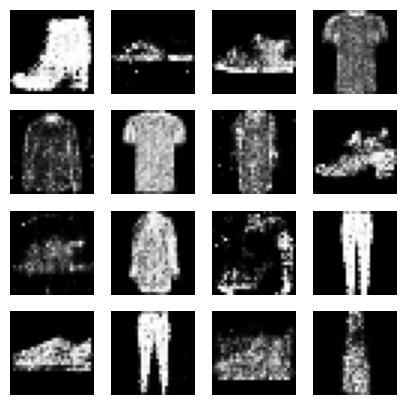

Epoch [41/50] | D Loss: 1.2683 | G Loss: 0.9253
Epoch [42/50] | D Loss: 1.2779 | G Loss: 0.7979
Epoch [43/50] | D Loss: 1.2415 | G Loss: 1.0195
Epoch [44/50] | D Loss: 1.3182 | G Loss: 0.9447
Epoch [45/50] | D Loss: 1.2604 | G Loss: 0.9946
Epoch [46/50] | D Loss: 1.2997 | G Loss: 0.9481
Epoch [47/50] | D Loss: 1.2398 | G Loss: 0.8729
Epoch [48/50] | D Loss: 1.3434 | G Loss: 1.0760
Epoch [49/50] | D Loss: 1.2769 | G Loss: 0.9450
Epoch [50/50] | D Loss: 1.2510 | G Loss: 1.0422


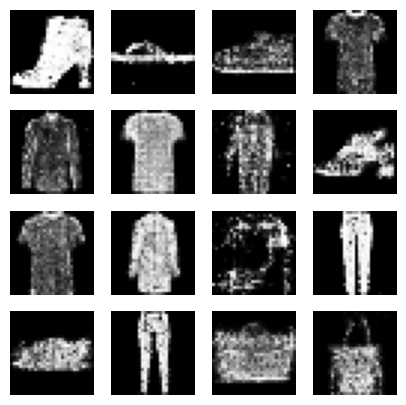

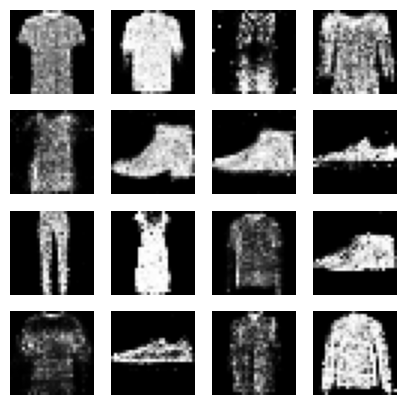

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# =======================
# 1. Device Configuration
# =======================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =======================
# 2. Data Loading (MNIST)
# =======================
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # Normalize to [-1, 1] for better GAN stability
])

train_dataset = torchvision.datasets.FashionMNIST(root="./data", train=True, transform=transform, download=True)
train_dataloader = DataLoader(train_dataset, batch_size=128, shuffle=True)

# =======================
# 3. Define Generator & Discriminator
# =======================

# Generator
class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 28 * 28),
            nn.Tanh()  # Outputs between -1 and 1 (match input normalization)
        )

    def forward(self, z):
        return self.model(z).view(-1, 1, 28, 28)  # Reshape to image format

# Discriminator
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(28 * 28, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()  # Output probability (0 to 1)
        )

    def forward(self, x):
        x = x.view(-1, 28 * 28)  # Flatten image
        return self.model(x)

# Instantiate models
noise_dim = 100
generator = Generator(noise_dim).to(device)
discriminator = Discriminator().to(device)

# =======================
# 4. Define Loss & Optimizers
# =======================
criterion = nn.BCELoss()  # Binary Cross-Entropy Loss
lr = 0.0002

optimizer_G = optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D = optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))

# =======================
# 5. Training Loop
# =======================
epochs = 50
fixed_noise = torch.randn(16, noise_dim, device=device)  # Fixed noise for visualization

for epoch in range(epochs):
    for real_imgs, _ in train_dataloader:
        batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        # ---- Train Discriminator ----
        optimizer_D.zero_grad()
        
        # Real images (label = 1)
        real_labels = torch.ones(batch_size, 1, device=device)
        real_outputs = discriminator(real_imgs)
        d_loss_real = criterion(real_outputs, real_labels)

        # Fake images (label = 0)
        noise = torch.randn(batch_size, noise_dim, device=device)
        fake_imgs = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device)
        fake_outputs = discriminator(fake_imgs.detach())
        d_loss_fake = criterion(fake_outputs, fake_labels)

        # Total discriminator loss
        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        optimizer_D.step()

        # ---- Train Generator ----
        optimizer_G.zero_grad()

        # Generate fake images & classify them
        fake_outputs = discriminator(fake_imgs)  # No detach() - we want gradients
        g_loss = criterion(fake_outputs, real_labels)  # Trick discriminator (want 1)

        g_loss.backward()
        optimizer_G.step()

    # Print progress
    print(f"Epoch [{epoch+1}/{epochs}] | D Loss: {d_loss:.4f} | G Loss: {g_loss:.4f}")

    # Generate and visualize images every 10 epochs
    if (epoch + 1) % 10 == 0:
        with torch.no_grad():
            generated_imgs = generator(fixed_noise).cpu()
        
        fig, axes = plt.subplots(4, 4, figsize=(5, 5))
        for i, ax in enumerate(axes.flatten()):
            ax.imshow(generated_imgs[i].squeeze(), cmap="gray")
            ax.axis("off")
        plt.show()

# =======================
# 6. Generate New Images
# =======================
with torch.no_grad():
    random_noise = torch.randn(16, noise_dim, device=device)
    generated_imgs = generator(random_noise).cpu()

fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(generated_imgs[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.show()
